# PydanticAT together with Pydantic Models

In [55]:
from model import nvidia_model
from pydantic_ai import Agent

employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige. Simulera i detta formatet likt exemplet"
    """
        name: "Bertil",
        age: 40,
        salary: 35000,
        role: "IT-supporter",
        city: "Göteborg"
    """
    )

result = await employee_simulator.run("Ge mig en data engineer som jobbar i stockholm")
print(result.output)

name: "Erik Lindberg",
age: 34,
salary: 62000,
role: "Data engineer",
city: "Stockholm"


## Forece a structured output using pydantic

In [56]:
from pydantic import BaseModel, Field

class EmployeeModel(BaseModel):
    name: str = Field(description="för och efternamn, inte jättelångt, svenska eller internationella namn")
    age: int = Field(description="ålder från 18 till 67 år", ge=18, le=67)
    salary: int = Field(description="lön mellan 30k-60k, ju mer senior position, desto högre lön", 
                        ge=30_000, 
                        le=60_000
                        )
    role:str = Field(description="yrke/roll")
    description: str = Field(description="kort beskrivning, 2 meningar på rollen")


employee1 = EmployeeModel(name="Bertil", age=40, salary=30_000, role="IT-supporter", description="Hjälper folk med IT")

employee1

EmployeeModel(name='Bertil', age=40, salary=30000, role='IT-supporter', description='Hjälper folk med IT')

In [57]:
employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige."
)

result = await employee_simulator.run("Ge mig en data engineer i stockholm", output_type=EmployeeModel)

employee2 = result.output
employee2

EmployeeModel(name='Erik Johansson', age=32, salary=52000, role='Data Engineer', description='Erik arbetar som Data Engineer i Stockholm och ansvarar för att designa, bygga och underhålla datapipeliner som stödjer företagets analys- och affärsbehov. Han har erfarenhet av molntjänster som Azure och GCP samt verktyg som Python, SQL och Spark.')

In [58]:
type(employee2)

__main__.EmployeeModel

In [59]:
employee2.name + " är cool"

'Erik Johansson är cool'

In [60]:
employee2.salary

52000

In [61]:
employee2.__dict__.keys()

dict_keys(['name', 'age', 'salary', 'role', 'description'])

In [62]:
employee2.__dict__.values()

dict_values(['Erik Johansson', 32, 52000, 'Data Engineer', 'Erik arbetar som Data Engineer i Stockholm och ansvarar för att designa, bygga och underhålla datapipeliner som stödjer företagets analys- och affärsbehov. Han har erfarenhet av molntjänster som Azure och GCP samt verktyg som Python, SQL och Spark.'])

In [63]:
for key, value in employee2.__dict__.items():
    print(f"{key}: {value}")

name: Erik Johansson
age: 32
salary: 52000
role: Data Engineer
description: Erik arbetar som Data Engineer i Stockholm och ansvarar för att designa, bygga och underhålla datapipeliner som stödjer företagets analys- och affärsbehov. Han har erfarenhet av molntjänster som Azure och GCP samt verktyg som Python, SQL och Spark.


## Simulate many employees

In [ ]:
result = await employee_simulator.run("Ge mig totalt 10 anställda inom IT/HR/marketing",
                                      output_type=list[EmployeeModel])

result

In [ ]:
employees = result.output

employees

In [66]:
salary = 0

for employee in employees:    
    salary += employee.salary

salary/len(employees)

43400.0

## Convert to datafarame

In [67]:
employees[0].model_dump()

{'name': 'Anna Svensson',
 'age': 29,
 'salary': 38000,
 'role': 'Systemutvecklare',
 'description': 'Utvecklar och underhåller webbapplikationer i ett agilt team. Har erfarenhet av JavaScript och molnbaserade lösningar.'}

In [68]:
import pandas as pd
df = pd.DataFrame([employee.model_dump() for employee in employees])
df.head()

,name,age,salary,role,description
0,Anna Svensson,29,38000,Systemutvecklare,Utvecklar och underhåller webbapplikationer i ...
1,Erik Johansson,34,45000,IT-säkerhetsspecialist,Ansvarar för företagets säkerhetsarbete och ri...
2,Maria Karlsson,26,33000,IT-supporttekniker,Hjälper kollegor med datorproblem och installa...
3,Lars Nilsson,42,56000,Molnarkitekt,Designar och implementerar molnlösningar för s...
4,Sara Andersson,31,37000,HR-assistent,Stödjer HR-avdelningen med administration och ...


In [69]:
df.to_csv("employees.csv", index=None)

<Axes: ylabel='name'>

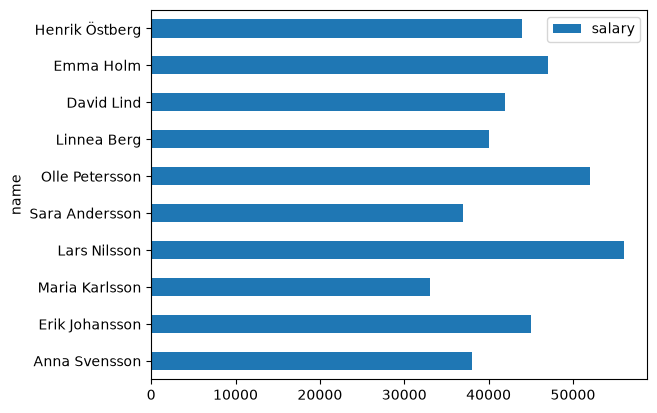

In [71]:
df.plot(kind = "barh", x = "name", y = "salary")